# 18 · Detrending and fitting together: a Gaussian process with the transit

**Level:** intermediate · **Prerequisites:** [11](11_your_first_fit_with_is.ipynb), [06](06_marginal_transit_model.ipynb) helps · **Run time:** ~1 min (most of it the download and the first compilation)

**Covers:** `MarginalTransitModel(..., gp=pizzetti.GP())`, a light curve that is not detrended, `gp_predict`, reading the GP parameters, a comparison with no detrending and with a biweight filter, when a GP helps and when to be careful

Tutorial 11 removed the stellar variability first and fitted the transits afterwards. That is two steps: the filter does not know the transit, and the fit does not know that the trend was uncertain. With `gp=` both happen in one step. The noise model holds an additive Gaussian process (GP), its parameters are sampled with the transit, and the limb darkening and the baseline are still integrated out exactly.

We fit K2-24 b, a sub-Saturn on a 21-day orbit. Its transits are about 2 ppt deep, and over the campaign the star drifts by about 8 ppt, so each transit sits on a different level and slope.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # lightkurve warns about an optional package
import math
import time as clock
import numpy as np
import matplotlib.pyplot as plt
import lightkurve as lk
import corner
from scipy.ndimage import median_filter
from wotan import flatten, transit_mask
import pizzetti

## Step 1: download the light curve

The EVEREST pipeline has removed K2's pointing systematics, but it keeps the star's own variability. One point every 30 minutes, for about 70 days. Period, mid-transit time and duration come from the literature (NASA Exoplanet Archive). K2-24 c transits too, and we will drop its transits.

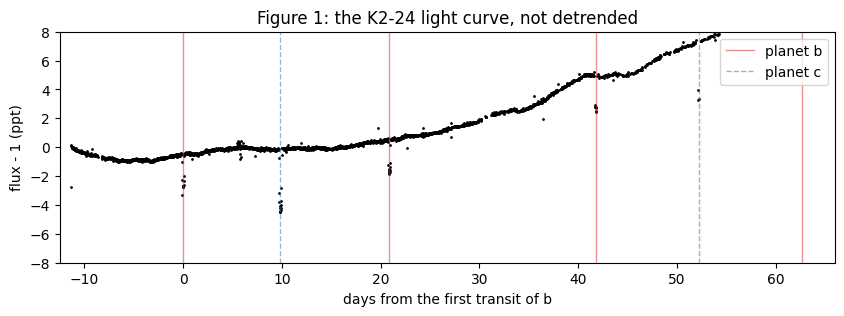

In [2]:
search = lk.search_lightcurve("K2-24", mission="K2", author="EVEREST", exptime=1800)
lc = search.download().remove_nans().normalize()
bjd = lc.time.jd
flux = np.asarray(lc.flux.value, dtype=float)

per, tc, t14 = 20.8895961, 2456905.79581, 5.38 / 24       # planet b: days, BJD, days
per_c, tc_c, t14_c = 42.34732, 2456957.98832, 6.50 / 24   # planet c
exposure = np.median(np.diff(bjd))                        # days

def phase_of(t, period, epoch):
    return (t - epoch + 0.5 * period) % period - 0.5 * period

plt.figure(figsize=(10, 3))
plt.plot(bjd - tc, 1e3 * (flux - 1), "k.", ms=2)
for e in np.arange(-1, 5):
    plt.axvline(e * per, color="C3", lw=1, alpha=0.5, label="planet b" if e == 0 else None)
for e in np.arange(-2, 3):
    plt.axvline(tc_c - tc + e * per_c, color="C0", lw=1, alpha=0.5, ls="--", label="planet c" if e == 0 else None)
plt.xlim(bjd[0] - tc, bjd[-1] - tc)
plt.ylim(-8, 8)                                           # a few thruster outliers lie far below
plt.xlabel("days from the first transit of b"); plt.ylabel("flux - 1 (ppt)"); plt.legend(loc="upper right")
plt.title("Figure 1: the K2-24 light curve, not detrended");

## Step 2: keep windows around the transits, in time order

We take ±3 durations around each transit of b: enough out-of-transit data for the GP to learn the trend from. Two things differ from tutorial 11:

- **The light curve is not folded.** A GP correlates neighbours in time, so `t` stays in ascending order and the transits keep their own epochs. `gp=` raises an error if `t` is not ascending.
- **Nothing is detrended.**

Outliers are removed per window, against a running median after dividing by a rough transit. Flux is deliberately not compared between windows: there the trend would look like an outlier.

161 points in 3 windows, 3 clipped, white noise 48 ppm per point


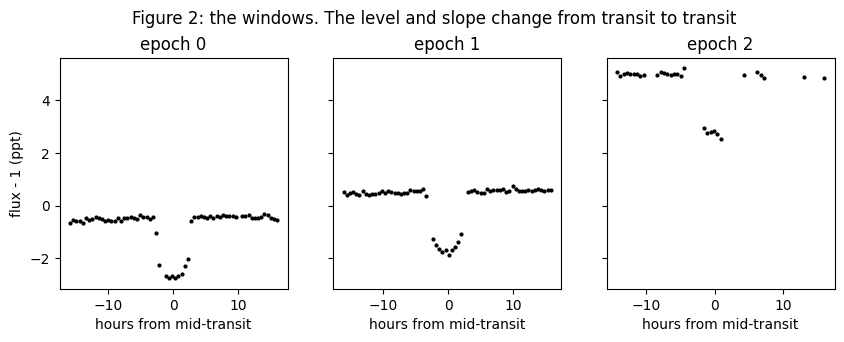

In [3]:
def start_params():
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = 0.0, per, 0.044, 28.0
    p.inc = math.degrees(math.acos(0.38 / 28.0))
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [0.4, 0.25]
    return p

K = 15                                                    # sub-exposures for the 30-minute cadence
t_all = bjd - tc
in_c = np.abs(phase_of(bjd, per_c, tc_c)) < 0.5 * (1.1 * t14_c + exposure)
phase = phase_of(t_all, per, 0.0)
epoch = np.round(t_all / per).astype(int)
near = (np.abs(phase) < 3 * t14) & ~in_c
near &= np.isin(epoch, np.unique(epoch[near & (np.abs(phase) < 0.5 * t14)]))      # windows with transit data
t, y, ep = t_all[near], flux[near], epoch[near]

# white noise per point, from point-to-point differences: insensitive to the trend
sigma = 1.4826 * np.median(np.abs(np.diff(y[np.abs(phase[near]) > 0.6 * t14]))) / math.sqrt(2)
p0 = start_params()
rough = pizzetti.TransitModel(p0, t, supersample_factor=K, exp_time=exposure, offsets="midpoint").light_curve(p0)
keep = np.ones(len(t), bool)
for e in np.unique(ep):
    m = ep == e
    r = y[m] / rough[m]
    keep[m] = np.abs(r - median_filter(r, size=5, mode="nearest")) < 5 * sigma
print(f"{near.sum()} points in {len(np.unique(ep))} windows, {(~keep).sum()} clipped, white noise {sigma * 1e6:.0f} ppm per point")
t, y, ep = t[keep], y[keep], ep[keep]

epochs = np.unique(ep)
fig, axs = plt.subplots(1, len(epochs), figsize=(10, 3), sharey=True)
for ax, e in zip(axs, epochs):
    m = ep == e
    ax.plot(24 * (t[m] - e * per), 1e3 * (y[m] - 1), "k.", ms=4)
    ax.set_title(f"epoch {e}"); ax.set_xlabel("hours from mid-transit")
axs[0].set_ylabel("flux - 1 (ppt)")
fig.suptitle("Figure 2: the windows. The level and slope change from transit to transit", y=1.04);

## Step 3: what if we do not detrend?

As a baseline, a plain `fit()` of these points with white noise. Each window has its own trend, but the model has one flat baseline `f0`.

In [4]:
free = ("t0", "rp", "a", "b")
kw = dict(free=free, bounds={"t0": (-0.5 * t14, 0.5 * t14), "rp": (1e-4, 0.5)},
          supersample_factor=K, exp_time=exposure, offsets="midpoint")

raw = pizzetti.MarginalTransitModel(start_params(), t, y, sigma, **kw).fit(seed=1)
print(raw.summary())

              median     -1sigma     +1sigma
t0      -0.004084966    0.000402    0.000396
rp        0.04318239    0.000128    0.000126
a           9.052993      0.0705      0.0679
b          0.9175998     0.00146     0.00152
q1         0.2902799     0.00422     0.00402
q2         0.9997952    0.000359    0.000152
f0          1.000901    4.43e-06     4.4e-06


## Step 4: the fit with a GP

One more argument. `pizzetti.GP()` adds three sampled parameters:

| label | meaning | default prior (log-uniform) |
|---|---|---|
| `ln_gp_amp` | rms of the GP, in flux units | 0.02 × median `yerr` to 0.2 × median flux |
| `ln_gp_tau` | its time scale in days | median cadence to 180 T14 |
| `ln_err_scale` | factor on `yerr` for the white noise | 1/3 to 3 |

`yerr` only has to be right within those limits. Every call that works without a GP works here: `fit()`, `FitResult`, `corner`, `EnsembleSampler`.

In [5]:
model = pizzetti.MarginalTransitModel(start_params(), t, y, sigma, gp=pizzetti.GP(), **kw)
start = clock.perf_counter()
result = model.fit(seed=1)
print(f"{clock.perf_counter() - start:.1f} s, {result.diagnostics['n_eval']} likelihood evaluations, "
      f"k-hat {result.diagnostics['khat']:.2f}, ESS {result.diagnostics['ess']:.0f}, is_ok = {result.diagnostics['is_ok']}\n")
print(result.summary())

1.1 s, 11826 likelihood evaluations, k-hat 0.41, ESS 1256, is_ok = True

                     median     -1sigma     +1sigma
t0              -0.00186669    0.000617    0.000596
rp               0.04402286    0.000514    0.000767
a                  30.10972         2.3       0.876
b                 0.2314999       0.152       0.211
ln_gp_amp         -5.564138       0.586       0.864
ln_gp_tau          2.666981       0.533       0.631
ln_err_scale      0.3338945      0.0578      0.0612
q1                0.2416217      0.0827        0.15
q2                0.5520706       0.223       0.247
f0                 1.001242     0.00323     0.00283


## Step 5: look at the GP

`model.gp_predict(row)` gives the GP at the data times for one row of `result.samples`, given that row's transit. So `y - gp_predict(row)` is the detrended light curve. With `t=` it also gives the GP at any other times, which we use to draw smooth curves between the data points. We evaluate it for 100 posterior draws: the band shows how well the baseline is known across the transit.

residual rms 64 ppm, fitted white noise 66 ppm


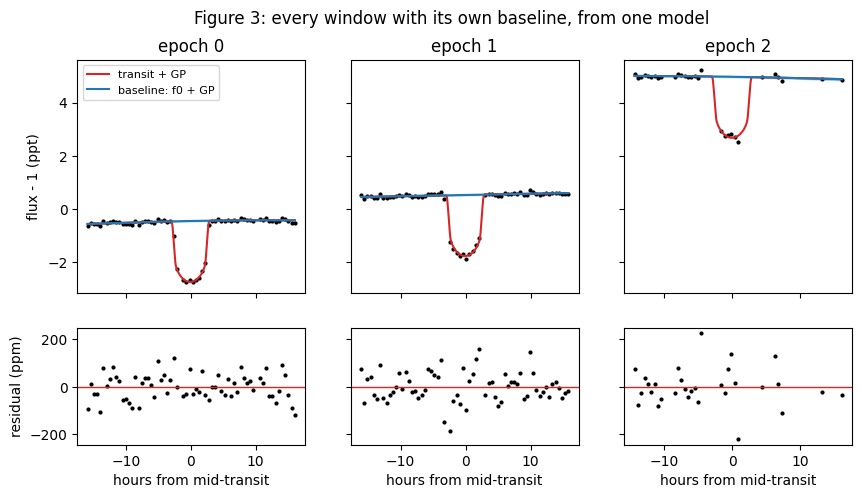

In [6]:
labels = list(result.labels)
rng = np.random.default_rng(2)
rows = result.samples[rng.choice(len(result.samples), 100, replace=False)]
trends = np.array([model.gp_predict(row) for row in rows])

def transit_of(row, times):
    """The transit of one row of samples, including the baseline f0."""
    c = dict(zip(labels, row))
    p = pizzetti.TransitParams()
    p.t0, p.per, p.rp, p.a = c["t0"], per, c["rp"], c["a"]
    p.inc = math.degrees(math.acos(c["b"] / c["a"]))
    sq = math.sqrt(c["q1"])
    p.ecc, p.w, p.limb_dark, p.u = 0.0, 90.0, "quadratic", [2 * sq * c["q2"], sq * (1 - 2 * c["q2"])]
    tm = pizzetti.TransitModel(p, times, supersample_factor=K, exp_time=exposure, offsets="midpoint")
    return c["f0"] * tm.light_curve(p)

transits = np.array([transit_of(row, t) for row in rows])
# The constant part of the GP is degenerate with f0, so we plot their sum: the baseline under the transit
full = (transits + trends).mean(axis=0)                   # the model at the data times, for the residuals
f0s = rows[:, labels.index("f0")]

fig, axs = plt.subplots(2, len(epochs), figsize=(10, 5), sharex="col", sharey="row", gridspec_kw=dict(height_ratios=[2, 1]))
for j, e in enumerate(epochs):
    m = ep == e
    h = 24 * (t[m] - e * per)
    fine = np.linspace(t[m][0], t[m][-1], 400)            # the curves between the data points
    hf = 24 * (fine - e * per)
    pred = [model.gp_predict(row, t=fine, return_var=True) for row in rows]
    gp_f = np.array([p[0] for p in pred])
    base_f = gp_f + f0s[:, None]
    base_sd = np.sqrt(base_f.var(axis=0) + np.mean([p[1] for p in pred], axis=0))
    tr_f = np.array([transit_of(row, fine) for row in rows])
    axs[0, j].plot(h, 1e3 * (y[m] - 1), "k.", ms=4)
    axs[0, j].plot(hf, 1e3 * ((tr_f + gp_f).mean(axis=0) - 1), "C3", lw=1.5, label="transit + GP")
    axs[0, j].plot(hf, 1e3 * (base_f.mean(axis=0) - 1), "C0", lw=1.5, label="baseline: f0 + GP")
    axs[0, j].fill_between(hf, 1e3 * (base_f.mean(axis=0) - base_sd - 1), 1e3 * (base_f.mean(axis=0) + base_sd - 1), color="C0", alpha=0.3)
    axs[0, j].set_title(f"epoch {e}")
    axs[1, j].plot(h, 1e6 * (y[m] - full[m]), "k.", ms=4); axs[1, j].axhline(0, color="C3", lw=1)
    axs[1, j].set_xlabel("hours from mid-transit")
axs[0, 0].set_ylabel("flux - 1 (ppt)"); axs[1, 0].set_ylabel("residual (ppm)"); axs[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("Figure 3: every window with its own baseline, from one model");
print(f"residual rms {(y - full).std() * 1e6:.0f} ppm, fitted white noise {sigma * math.exp(np.median(result.samples[:, labels.index('ln_err_scale')])) * 1e6:.0f} ppm")

## Step 6: what a filter would do

For comparison, the two-step route of tutorial 11: a biweight filter with a 2-day window and the transits masked, ±1.5 durations around each transit, white noise from the scatter outside the transit, then a plain `fit()`.

In [7]:
ok = np.isfinite(flux) & ~in_c
mask = transit_mask(time=t_all[ok], period=per, duration=1.1 * t14 + exposure, T0=0.0)
flat = flatten(t_all[ok], flux[ok], method="biweight", window_length=2.0, mask=mask)
good = np.isfinite(flat)
tf, yf = t_all[ok][good], flat[good]
pf = phase_of(tf, per, 0.0)
win = np.abs(pf) < 1.5 * t14
win &= np.isin(np.round(tf / per).astype(int), np.unique(np.round(tf[win & (np.abs(pf) < 0.5 * t14)] / per).astype(int)))
tf, yf, pf = tf[win], yf[win], pf[win]
sig_f = 1.4826 * np.median(np.abs(yf[np.abs(pf) > 0.5 * t14 + exposure] - np.median(yf[np.abs(pf) > 0.5 * t14 + exposure])))
rf = pizzetti.TransitModel(p0, tf, supersample_factor=K, exp_time=exposure, offsets="midpoint").light_curve(p0)
keepf = np.ones(len(tf), bool)
for e in np.unique(np.round(tf / per).astype(int)):
    m = np.round(tf / per).astype(int) == e
    r = yf[m] / rf[m]
    keepf[m] = np.abs(r - median_filter(r, size=5, mode="nearest")) < 5 * sig_f
biweight = pizzetti.MarginalTransitModel(start_params(), tf[keepf], yf[keepf], sig_f, **kw).fit(seed=1)
print(f"{keepf.sum()} points, white noise {sig_f * 1e6:.0f} ppm, k-hat {biweight.diagnostics['khat']:.2f}\n")
print(biweight.summary())

81 points, white noise 55 ppm, k-hat 0.42

              median     -1sigma     +1sigma
t0      -0.001976616    0.000489    0.000494
rp        0.04409601     0.00042    0.000665
a           30.33817        2.04       0.734
b          0.2187297       0.151       0.196
q1         0.2339035        0.08       0.123
q2         0.5740032       0.193       0.243
f0          1.000022    7.44e-06     7.8e-06


Now all three posteriors of the transit parameters, using the exact weighted draws. T14 is computed from each draw.

no detrending          Rp/R* = 0.04318 +0.00013 -0.00013
biweight, then fit     Rp/R* = 0.04409 +0.00066 -0.00043
GP with the transit    Rp/R* = 0.04402 +0.00076 -0.00051


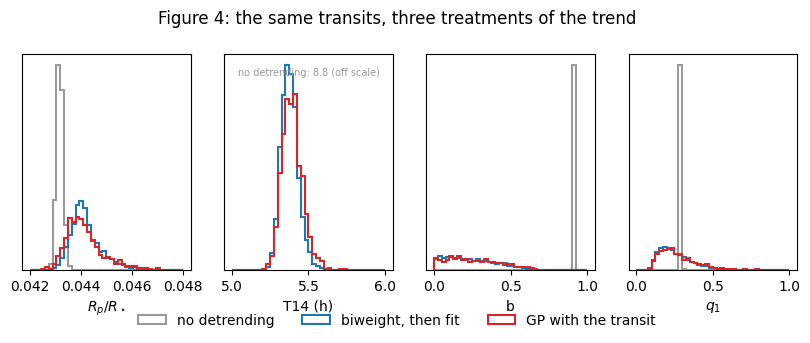

In [8]:
def t14_hours(c):
    return 24 * per / np.pi * np.arcsin(np.sqrt(np.clip((1 + c["rp"]) ** 2 - c["b"] ** 2, 0, None)) / np.sqrt(c["a"] ** 2 - c["b"] ** 2))

runs = [("no detrending", raw, "0.6"), ("biweight, then fit", biweight, "C0"), ("GP with the transit", result, "C3")]
fig, axs = plt.subplots(1, 4, figsize=(10, 2.8))
names = [("rp", r"$R_p/R_\star$"), ("T14", "T14 (h)"), ("b", "b"), ("q1", r"$q_1$")]
rows_t = []
for lab, res_, col in runs:
    c = {n: res_.weighted_samples[:, j] for j, n in enumerate(res_.labels)}
    c["T14"] = t14_hours(c)
    for ax, (n, tl) in zip(axs, names):
        lo, hi = {"rp": (0.042, 0.048), "T14": (5.0, 6.0), "b": (0, 1), "q1": (0, 1)}[n]
        if ((c[n] > lo) & (c[n] < hi)).any():
            ax.hist(c[n], bins=40, range=(lo, hi), weights=res_.weights, histtype="step", color=col, lw=1.5, label=lab, density=True)
        else:
            ax.text(0.5, 0.9, f"{lab}: {np.median(c[n]):.1f} (off scale)", transform=ax.transAxes, ha="center", fontsize=7, color=col)
        ax.set_xlabel(tl); ax.set_yticks([])
    o = np.argsort(c["rp"]); cw = np.cumsum(res_.weights[o]); q = np.interp([0.16, 0.5, 0.84], cw / cw[-1], c["rp"][o])
    rows_t.append(f"{lab:22s} Rp/R* = {q[1]:.5f} +{q[2] - q[1]:.5f} -{q[1] - q[0]:.5f}")
fig.legend(*axs[0].get_legend_handles_labels(), loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.14), frameon=False)
fig.suptitle("Figure 4: the same transits, three treatments of the trend", y=1.04)
print("\n".join(rows_t))

Without detrending, the posterior is narrow and in the wrong place. One flat baseline cannot explain windows at different levels, and the white-noise model takes the mismatch at face value: `b` runs to 0.92, `a/R*` to 9 instead of about 30, the duration to almost 9 hours, and `q2` to its physical limit, all with tiny error bars. The filter and the GP agree with each other. The GP needed no choice of filter window, and its error bars already include the uncertainty of the trend across the transit.

## Step 7: the planet

The corner plot of the planet's parameters shows the GP fit and the biweight fit together. Both have the same shape: the familiar ridge in which a larger `b` goes with a smaller `a/R*` and a larger `Rp/R*`, cut off at `b = 0`.

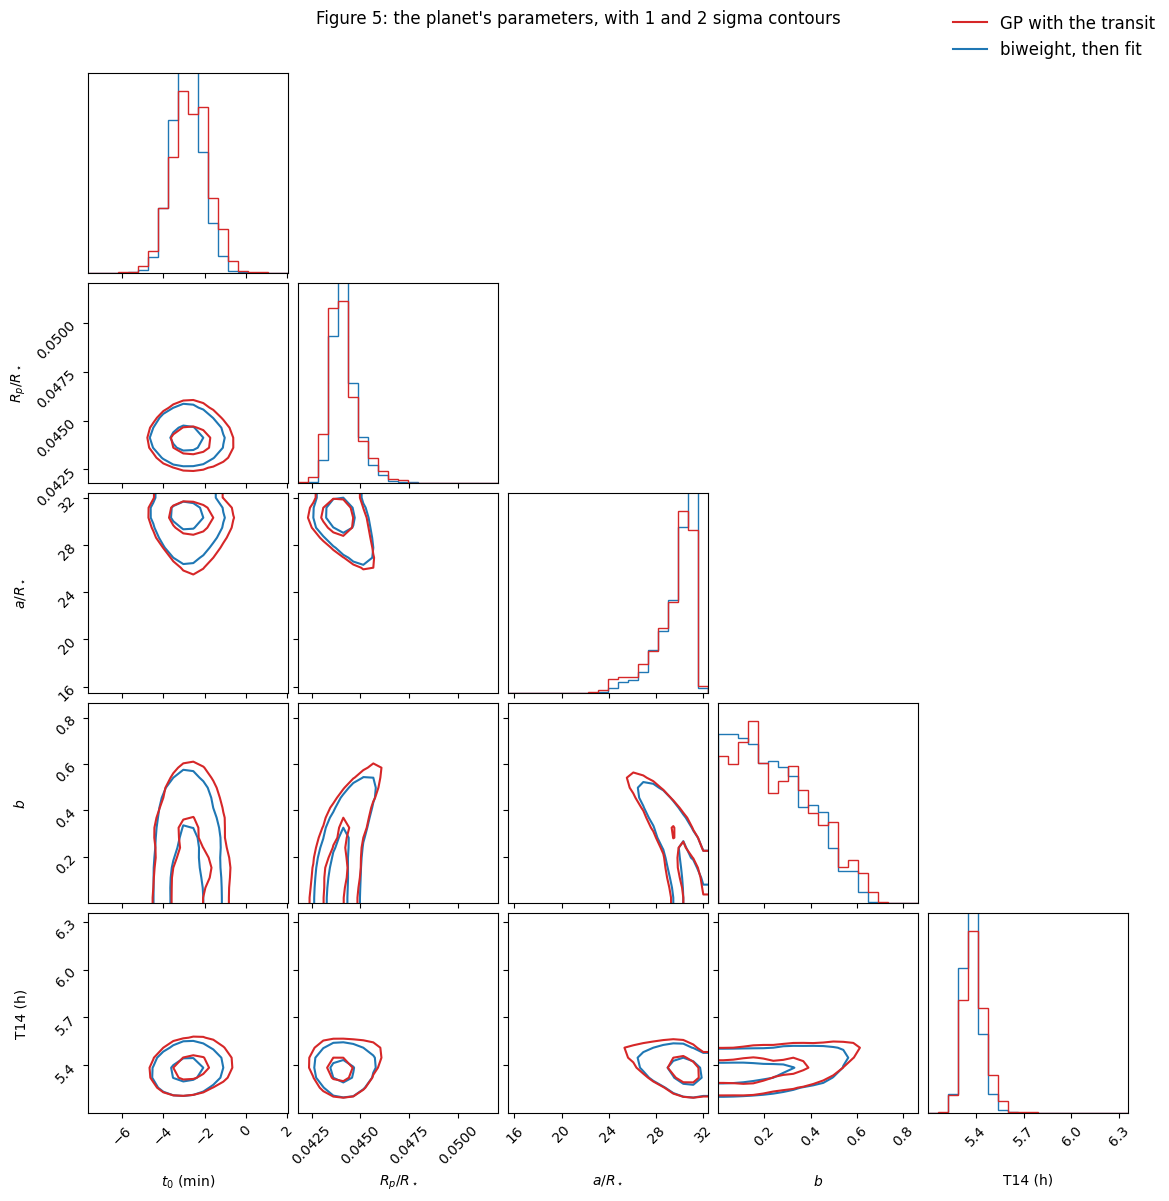

In [9]:
def planet_columns(res_):
    c = {n: res_.weighted_samples[:, j] for j, n in enumerate(res_.labels)}
    return np.column_stack([24 * 60 * c["t0"], c["rp"], c["a"], c["b"], t14_hours(c)])

names_p = [r"$t_0$ (min)", r"$R_p/R_\star$", r"$a/R_\star$", r"$b$", "T14 (h)"]
Xg, Xb = planet_columns(result), planet_columns(biweight)
ranges = [tuple(np.percentile(np.concatenate([Xg[:, j], Xb[:, j]]), [0.3, 99.7])) for j in range(5)]
fig = corner.corner(Xb, weights=biweight.weights, labels=names_p, range=ranges, color="C0", smooth=1.0, hist_kwargs=dict(density=True),
                    plot_datapoints=False, plot_density=False, no_fill_contours=True, levels=(0.39, 0.86))
corner.corner(Xg, weights=result.weights, range=ranges, color="C3", smooth=1.0, hist_kwargs=dict(density=True), fig=fig,
              plot_datapoints=False, plot_density=False, no_fill_contours=True, levels=(0.39, 0.86))
fig.legend(handles=[plt.Line2D([], [], color="C3", label="GP with the transit"), plt.Line2D([], [], color="C0", label="biweight, then fit")],
           loc="upper right", frameon=False, fontsize=12)
fig.suptitle("Figure 5: the planet's parameters, with 1 and 2 sigma contours", y=1.02);

## Step 8: the GP parameters

The hyperparameters are worth reading. Here the corner plot shows the two parameters of the GP, the white noise, and `Rp/R*`.

amplitude 3833 ppm (2133 to 9096), time scale 14.4 d (8.4 to 27.0)


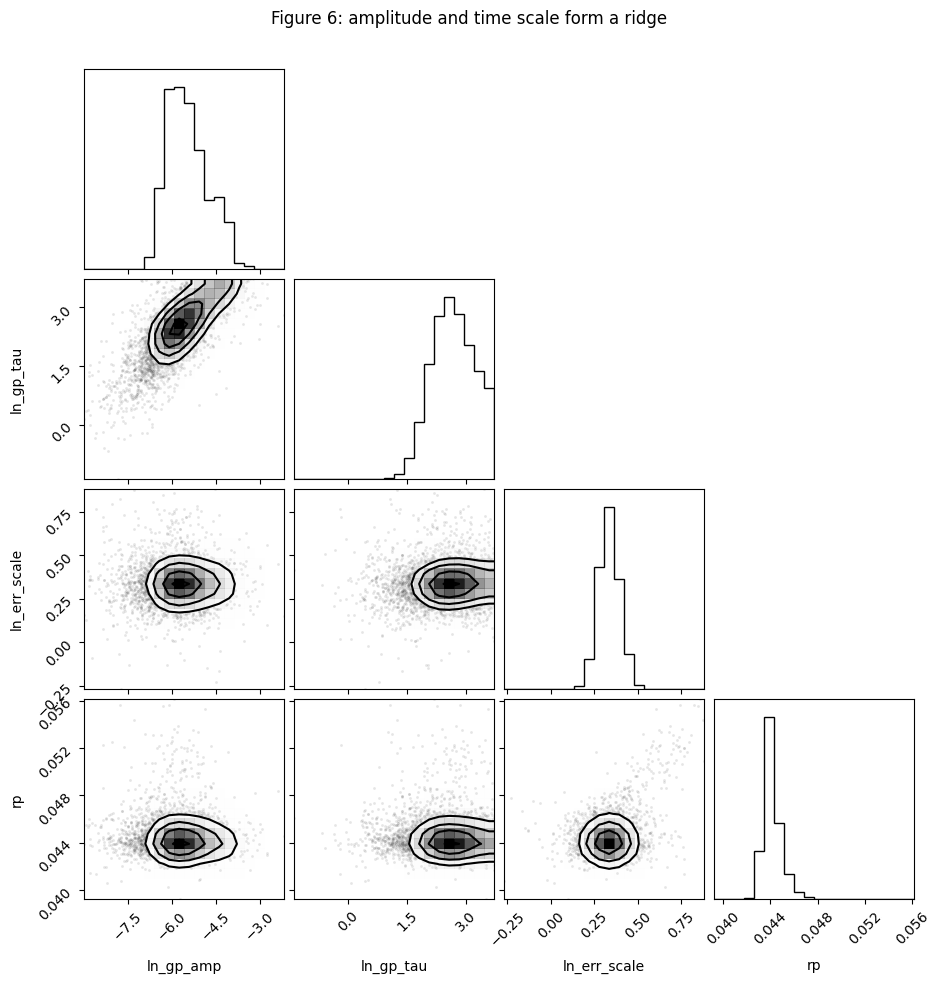

In [10]:
idx = [labels.index(n) for n in ("ln_gp_amp", "ln_gp_tau", "ln_err_scale", "rp")]
fig = corner.corner(result.weighted_samples[:, idx], weights=result.weights, labels=[labels[i] for i in idx], smooth=1.0)
fig.suptitle("Figure 6: amplitude and time scale form a ridge", y=1.02);
q = np.percentile(result.samples[:, idx[:2]], [16, 50, 84], axis=0)
print(f"amplitude {1e6 * math.exp(q[1, 0]):.0f} ppm ({1e6 * math.exp(q[0, 0]):.0f} to {1e6 * math.exp(q[2, 0]):.0f}), "
      f"time scale {math.exp(q[1, 1]):.1f} d ({math.exp(q[0, 1]):.1f} to {math.exp(q[2, 1]):.1f})")

The time scale is much longer than a window (1.3 days). Over such a stretch the GP is a smooth curve whose constant part is degenerate with `f0` and whose curvature goes as amplitude / time scale. So the data fix that ratio, not the two separately. That is the ridge. It is not a problem here: `Rp/R*` does not depend on where along the ridge the fit sits. The prior only limits how far the ridge extends, and it does reach the upper bound on the time scale (180 T14 = 40 days), which is why `ln_gp_tau` looks cut off. The white noise comes out 1.4 × above the point-to-point estimate we passed as `yerr`, within the allowed factor of 3.

## When is this worth it?

**Use it when** the trend is hard to filter: its time scale is comparable to the window a filter would need, the transits are long, or you do not want to choose a window. On 14 raw Kepler, K2 and TESS light curves, 10 agreed with biweight fits within 0.4 σ. Simulated trends near the transit's time scale gave honest error bars where two-step fits were overconfident (rms z of R_p/R_★ of 0.55, against 1.6–1.8, in 8 noise realisations).

**Be careful when** the GP's time scale comes close to T14 and its amplitude far exceeds the depth. On very active stars (AU Mic b, DS Tuc A b) the GP gave R_p/R_★ 2–3 σ from biweight fits. The fit converges, but a single-time-scale GP may then absorb part of the transit, and it is not yet established which is right. Compare with a filter, and test with injected transits.

**Good to know:**
- The GP is *additive*. For trends of a few per cent the depth changes by a similar fraction of itself.
- Flares and other outliers are not modelled: clip them first.
- Cost: every evaluation also whitens the data at O(N), so a fit takes several times longer than the two-step fit (figures in the [documentation](https://pizzetti.readthedocs.io/en/latest/marginal.html#correlated-noise-a-gaussian-process)).
- Scope: quadratic law, primary transits, `ld_prior` "physical" or a callable. Other laws raise `NotImplementedError`.

**Options:**
```python
pizzetti.GP(tau=0.5)                       # a number holds a parameter fixed: a known time scale, in days
pizzetti.GP(err_scale=1.0)                 # trust yerr
pizzetti.GP(amp=(1e-4, 1e-2), tau=(0.1, 5.0))     # tuple: bounds of the log-uniform prior

def log_prior(d):                          # any prior, also on the GP's sampled logarithms, by label
    return -0.5 * ((d["ln_gp_tau"] - np.log(1.0)) / 0.5) ** 2
```

## What you learned

- `gp=pizzetti.GP()` fits the correlated noise together with the transit; limb darkening and baseline remain integrated out, and `fit()`, `FitResult` and `EnsembleSampler` work as before.
- The light curve must stay in time order, with enough data around each transit to show the trend.
- `gp_predict` gives the trend and the detrended light curve for any posterior draw.
- `ln_gp_amp` and `ln_gp_tau` show what the data constrain. A trend slower than the windows fixes only their ratio.

**Next:** [the theory and the cost](https://pizzetti.readthedocs.io/en/latest/marginal.html#correlated-noise-a-gaussian-process), [tutorial 15](15_when_the_profile_is_not_enough.ipynb) for reading `diagnostics`.